# 06. Network-Level Neural Characterization

## Aim

This analysis examined whether the five baseline-defined attention–motivation
phenotypes differed in cortical network-level activation during working-memory
load (`2-back > 0-back`).

Phenotypes were defined using baseline (`ses-1`) behavioral and self-report
data. Neural outcomes were derived from the Penn LEAD task-contrast pipeline
using the `rtdur` model.

For each participant, the official subject-level contrast estimate incorporates
all usable n-back runs/sessions that passed the Penn LEAD task-contrast QC
pipeline. Therefore, the neural outcome should not be interpreted as a
baseline-only fMRI measure.

Primary analyses used participants with an available official subject-level
`twoBackMinusZeroBack` effect map. A sensitivity analysis excluding participants
whose neural estimate did not include `ses-1` was additionally planned.

Cortical activation was summarized using the Schaefer 100-parcel,
7-network atlas.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd

import nibabel as nib
import matplotlib.pyplot as plt
import seaborn as sns

from nilearn import datasets
from nilearn.maskers import NiftiLabelsMasker

from scipy import stats
from statsmodels.stats.multitest import multipletests


PROJECT_DIR = Path("/Users/hyuna/OpenNeuro/ds007116")
OPENNEURO_DIR = Path("/Users/hyuna/OpenNeuro/ds007116")

DERIVED_DIR = PROJECT_DIR / "derived"
RESULTS_DIR = PROJECT_DIR / "results" / "summary_tables"
FIGURE_DIR = PROJECT_DIR / "figures"

RTDUR_DIR = (
    OPENNEURO_DIR
    / "derivatives"
    / "level-subject_task-fracback_model-rtdur"
)

CLUSTER_FILE = DERIVED_DIR / "gmm_cluster_assignments_k5.csv"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Cluster file:", CLUSTER_FILE.exists())
print("RTDur directory:", RTDUR_DIR.exists())

Cluster file: True
RTDur directory: True


In [2]:
cluster_df = pd.read_csv(CLUSTER_FILE)

print(cluster_df.shape)
display(cluster_df.head())

print("\nCluster sizes:")
print(cluster_df["cluster"].value_counts().sort_index())

(92, 4)


,participant_id,session_id,cluster,prob
0,sub-138950,ses-1,4,0.986002
1,sub-19861,ses-1,1,0.997255
2,sub-20125,ses-1,1,0.983757
3,sub-20139,ses-1,1,0.999997
4,sub-20141,ses-1,1,1.000000



Cluster sizes:
cluster
0     6
1    41
2     9
3     7
4    29
Name: count, dtype: int64


In [3]:
def find_rtdur_effect_maps(participant_id):
    sub = str(participant_id)

    if not sub.startswith("sub-"):
        sub = f"sub-{sub}"

    pattern = (
        f"**/{sub}*task-nback*"
        f"contrast-twoBackMinusZeroBack*"
        f"stat-effect_statmap.nii.gz"
    )

    return sorted(RTDUR_DIR.glob(pattern))


records = []

for _, row in cluster_df.iterrows():
    pid = row["participant_id"]
    maps = find_rtdur_effect_maps(pid)

    records.append({
        "participant_id": pid,
        "session_id": row["session_id"],
        "cluster": row["cluster"],
        "n_maps": len(maps),
        "map_path": str(maps[0]) if len(maps) == 1 else None
    })

brain_df = pd.DataFrame(records)

print(brain_df["n_maps"].value_counts().sort_index())

display(
    pd.crosstab(
        brain_df["cluster"],
        brain_df["n_maps"],
        margins=True
    )
)

n_maps
0    15
1    77
Name: count, dtype: int64


n_maps,0,1,All
cluster,,,
0,0,6,6
1,7,34,41
2,3,6,9
3,1,6,7
4,4,25,29
All,15,77,92


In [4]:
assert (brain_df["n_maps"] <= 1).all(), \
    "Some participants have more than one candidate effect map."

brain_cluster_df = (
    brain_df
    .loc[brain_df["n_maps"] == 1]
    .copy()
    .reset_index(drop=True)
)

print("Primary brain sample N =", len(brain_cluster_df))

print("\nCluster sizes:")
print(
    brain_cluster_df["cluster"]
    .value_counts()
    .sort_index()
)

Primary brain sample N = 77

Cluster sizes:
cluster
0     6
1    34
2     6
3     6
4    25
Name: count, dtype: int64


In [5]:
geometry_records = []

for path in brain_cluster_df["map_path"]:
    img = nib.load(path)

    geometry_records.append({
        "map_path": path,
        "shape": img.shape,
        "voxel_x": img.header.get_zooms()[0],
        "voxel_y": img.header.get_zooms()[1],
        "voxel_z": img.header.get_zooms()[2],
        "affine": tuple(np.round(img.affine.flatten(), 5))
    })

geometry_df = pd.DataFrame(geometry_records)

print("Unique shapes:")
print(geometry_df["shape"].value_counts())

print("\nUnique voxel sizes:")
print(
    geometry_df[
        ["voxel_x", "voxel_y", "voxel_z"]
    ].drop_duplicates()
)

print("\nNumber of unique affines:")
print(geometry_df["affine"].nunique())

Unique shapes:
shape
(91, 109, 91)    77
Name: count, dtype: int64

Unique voxel sizes:
   voxel_x  voxel_y  voxel_z
0      2.0      2.0      2.0

Number of unique affines:
1


In [6]:
atlas = datasets.fetch_atlas_schaefer_2018(
    n_rois=100,
    yeo_networks=7,
    resolution_mm=2
)

atlas_img = nib.load(atlas.maps)

print("Atlas path:")
print(atlas.maps)

print("\nAtlas shape:")
print(atlas_img.shape)

print("\nAtlas voxel size:")
print(atlas_img.header.get_zooms()[:3])

print("\nNumber of labels:")
print(len(atlas.labels))

print("\nFirst 10 labels:")
for label in atlas.labels[:10]:
    print(label)

[fetch_atlas_schaefer_2018] Dataset directory found: /Users/hyuna/nilearn_data/schaefer_2018
Atlas path:
/Users/hyuna/nilearn_data/schaefer_2018/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_2mm.nii.gz

Atlas shape:
(91, 109, 91)

Atlas voxel size:
(np.float32(2.0), np.float32(2.0), np.float32(2.0))

Number of labels:
101

First 10 labels:
Background
7Networks_LH_Vis_1
7Networks_LH_Vis_2
7Networks_LH_Vis_3
7Networks_LH_Vis_4
7Networks_LH_Vis_5
7Networks_LH_Vis_6
7Networks_LH_Vis_7
7Networks_LH_Vis_8
7Networks_LH_Vis_9


In [8]:
from nilearn.image import resample_to_img

example_img = nib.load(
    brain_cluster_df.loc[0, "map_path"]
)

atlas_resampled = resample_to_img(
    atlas_img,
    example_img,
    interpolation="nearest",
    force_resample=True,
    copy_header=True
)

print("Effect map shape:", example_img.shape)
print("Resampled atlas shape:", atlas_resampled.shape)

print(
    "Affines equal after resampling:",
    np.allclose(
        example_img.affine,
        atlas_resampled.affine,
        atol=1e-5
    )
)

atlas_values = np.unique(
    atlas_resampled.get_fdata()
)

print("Number of unique atlas values:", len(atlas_values))
print("First values:", atlas_values[:10])
print("Last values:", atlas_values[-10:])

Effect map shape: (91, 109, 91)
Resampled atlas shape: (91, 109, 91)
Affines equal after resampling: True
Number of unique atlas values: 101
First values: [0. 1. 2. 3. 4. 5. 6. 7. 8. 9.]
Last values: [ 91.  92.  93.  94.  95.  96.  97.  98.  99. 100.]


In [9]:
labels = [
    x.decode("utf-8") if isinstance(x, bytes) else str(x)
    for x in atlas.labels
]

print("Number of labels:", len(labels))

for i, label in enumerate(labels[:15]):
    print(i, label)

Number of labels: 101
0 Background
1 7Networks_LH_Vis_1
2 7Networks_LH_Vis_2
3 7Networks_LH_Vis_3
4 7Networks_LH_Vis_4
5 7Networks_LH_Vis_5
6 7Networks_LH_Vis_6
7 7Networks_LH_Vis_7
8 7Networks_LH_Vis_8
9 7Networks_LH_Vis_9
10 7Networks_LH_SomMot_1
11 7Networks_LH_SomMot_2
12 7Networks_LH_SomMot_3
13 7Networks_LH_SomMot_4
14 7Networks_LH_SomMot_5


In [10]:
masker = NiftiLabelsMasker(
    labels_img=atlas_resampled,
    standardize=False,
    resampling_target=None
)

parcel_rows = []

for _, row in brain_cluster_df.iterrows():

    img = nib.load(row["map_path"])

    values = masker.fit_transform(img).squeeze()

    parcel_rows.append({
        "participant_id": row["participant_id"],
        "cluster": row["cluster"],
        "values": values
    })

print("Participants extracted:", len(parcel_rows))
print("Number of parcels:", len(parcel_rows[0]["values"]))

/var/folders/gb/5qdt5csd02b2qys67tjhsygc0000gn/T/ipykernel_89231/3639505814.py:13: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  values = masker.fit_transform(img).squeeze()
/var/folders/gb/5qdt5csd02b2qys67tjhsygc0000gn/T/ipykernel_89231/3639505814.py:13: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  values = masker.fit_transform(img).squeeze()
/var/folders/gb/5qdt5csd02b2qys67tjhsygc0000gn/T/ipykernel_89231/3639505814.py:13: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  values = masker.fit_transform(img).squeeze()
/var/folders/gb/5qdt5csd02b2qys67tjhsygc0000gn/T/ipykernel_89231/3639505814.py:13: FutureWarning: boolean values for 'standardize' will 

Participants extracted: 77
Number of parcels: 100


/var/folders/gb/5qdt5csd02b2qys67tjhsygc0000gn/T/ipykernel_89231/3639505814.py:13: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  values = masker.fit_transform(img).squeeze()
/var/folders/gb/5qdt5csd02b2qys67tjhsygc0000gn/T/ipykernel_89231/3639505814.py:13: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  values = masker.fit_transform(img).squeeze()


In [11]:
parcel_matrix = np.vstack(
    [x["values"] for x in parcel_rows]
)

print("Parcel matrix shape:", parcel_matrix.shape)
print("NaN count:", np.isnan(parcel_matrix).sum())
print("Inf count:", np.isinf(parcel_matrix).sum())

print(
    "Value range:",
    np.nanmin(parcel_matrix),
    np.nanmax(parcel_matrix)
)

Parcel matrix shape: (77, 100)
NaN count: 0
Inf count: 0
Value range: -2.0434497985633056 1.0093867109182173


### Atlas alignment

The subject-level contrast maps and Schaefer atlas had identical image
dimensions and voxel resolution but differed in x-axis voxel orientation.
The Schaefer label image was therefore resampled to the contrast-map grid
using nearest-neighbor interpolation prior to parcel extraction. Nearest-
neighbor interpolation was used to preserve discrete atlas labels.

In [12]:
# Check all atlas labels
for i, label in enumerate(labels):
    print(i, label)

0 Background
1 7Networks_LH_Vis_1
2 7Networks_LH_Vis_2
3 7Networks_LH_Vis_3
4 7Networks_LH_Vis_4
5 7Networks_LH_Vis_5
6 7Networks_LH_Vis_6
7 7Networks_LH_Vis_7
8 7Networks_LH_Vis_8
9 7Networks_LH_Vis_9
10 7Networks_LH_SomMot_1
11 7Networks_LH_SomMot_2
12 7Networks_LH_SomMot_3
13 7Networks_LH_SomMot_4
14 7Networks_LH_SomMot_5
15 7Networks_LH_SomMot_6
16 7Networks_LH_DorsAttn_Post_1
17 7Networks_LH_DorsAttn_Post_2
18 7Networks_LH_DorsAttn_Post_3
19 7Networks_LH_DorsAttn_Post_4
20 7Networks_LH_DorsAttn_Post_5
21 7Networks_LH_DorsAttn_Post_6
22 7Networks_LH_DorsAttn_PrCv_1
23 7Networks_LH_DorsAttn_FEF_1
24 7Networks_LH_SalVentAttn_ParOper_1
25 7Networks_LH_SalVentAttn_FrOperIns_1
26 7Networks_LH_SalVentAttn_FrOperIns_2
27 7Networks_LH_SalVentAttn_PFCl_1
28 7Networks_LH_SalVentAttn_Med_1
29 7Networks_LH_SalVentAttn_Med_2
30 7Networks_LH_SalVentAttn_Med_3
31 7Networks_LH_Limbic_OFC_1
32 7Networks_LH_Limbic_TempPole_1
33 7Networks_LH_Limbic_TempPole_2
34 7Networks_LH_Cont_Par_1
35 7Networks_L

In [13]:
# Schaefer labels may or may not explicitly include background.
# Keep only the 100 parcel labels.

parcel_labels = [
    label for label in labels
    if label.lower() not in ["background", "0"]
]

print("Number of parcel labels:", len(parcel_labels))

assert len(parcel_labels) == 100
assert parcel_matrix.shape[1] == 100

Number of parcel labels: 100


In [14]:
def get_network(label):
    parts = label.split("_")

    # Expected:
    # 7Networks_LH_Vis_1
    # 7Networks_RH_Default_3
    return parts[2]


network_names = [get_network(x) for x in parcel_labels]

network_counts = pd.Series(network_names).value_counts()

print(network_counts)

Default        24
Vis            17
DorsAttn       15
SomMot         14
Cont           13
SalVentAttn    12
Limbic          5
Name: count, dtype: int64


In [15]:
print("\nUnique networks:")
print(sorted(set(network_names)))

print("\nNumber of networks:")
print(len(set(network_names)))


Unique networks:
['Cont', 'Default', 'DorsAttn', 'Limbic', 'SalVentAttn', 'SomMot', 'Vis']

Number of networks:
7


In [16]:
network_order = [
    "Vis",
    "SomMot",
    "DorsAttn",
    "SalVentAttn",
    "Limbic",
    "Cont",
    "Default"
]

network_matrix = np.zeros(
    (parcel_matrix.shape[0], len(network_order))
)

for j, network in enumerate(network_order):
    idx = [
        i for i, n in enumerate(network_names)
        if n == network
    ]

    network_matrix[:, j] = parcel_matrix[:, idx].mean(axis=1)

    print(
        f"{network:12s}: "
        f"{len(idx):2d} parcels"
    )

print("\nNetwork matrix shape:", network_matrix.shape)
print("NaN:", np.isnan(network_matrix).sum())
print("Inf:", np.isinf(network_matrix).sum())

Vis         : 17 parcels
SomMot      : 14 parcels
DorsAttn    : 15 parcels
SalVentAttn : 12 parcels
Limbic      :  5 parcels
Cont        : 13 parcels
Default     : 24 parcels

Network matrix shape: (77, 7)
NaN: 0
Inf: 0


In [17]:
network_df = pd.DataFrame(
    network_matrix,
    columns=network_order
)

network_df.insert(
    0,
    "cluster",
    brain_cluster_df["cluster"].to_numpy()
)

network_df.insert(
    0,
    "participant_id",
    brain_cluster_df["participant_id"].to_numpy()
)

display(network_df.head())

print(network_df.shape)

,participant_id,cluster,Vis,SomMot,DorsAttn,SalVentAttn,Limbic,Cont,Default
0,sub-19861,1,-0.298220,-0.241403,0.030804,0.008898,-0.162801,0.043716,-0.191311
1,sub-20139,1,-0.221823,-0.163815,0.032818,-0.087391,-0.185867,-0.006506,-0.226778
2,sub-20141,1,-0.157980,-0.078892,0.112747,0.050384,-0.124744,-0.104059,-0.163777
3,sub-20188,4,0.310141,0.126877,0.383589,0.235010,0.142028,0.240419,0.066225
4,sub-20214,1,-0.244914,-0.296924,-0.152512,-0.156296,-0.179604,-0.137859,-0.265796


(77, 9)


In [18]:
display(
    network_df[network_order]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
Vis,77.0,-0.130345,0.252953,-0.608717,-0.309609,-0.157980,0.008117,0.632467
SomMot,77.0,-0.102586,0.201869,-0.509539,-0.239812,-0.131056,-0.015419,0.545407
DorsAttn,77.0,0.041418,0.200394,-0.419596,-0.081573,0.021725,0.133831,0.591483
SalVentAttn,77.0,-0.048898,0.207163,-0.469864,-0.184156,-0.063015,0.050384,0.700296
Limbic,77.0,-0.056425,0.215614,-0.454424,-0.194054,-0.096977,0.060969,0.751112
Cont,77.0,0.032021,0.214918,-0.422614,-0.107813,0.004331,0.161946,0.689525
Default,77.0,-0.082374,0.216088,-0.441326,-0.242784,-0.091474,0.045317,0.691449


In [19]:
network_cluster_means = (
    network_df
    .groupby("cluster")[network_order]
    .mean()
)

display(network_cluster_means.round(4))

,Vis,SomMot,DorsAttn,SalVentAttn,Limbic,Cont,Default
cluster,,,,,,,
0,-0.3617,-0.2181,-0.2283,-0.2449,-0.2235,-0.1966,-0.2633
1,-0.0685,-0.0574,0.0995,-0.0080,0.0007,0.0920,-0.0310
2,-0.1795,-0.0544,-0.0185,-0.0388,-0.0535,-0.0766,-0.1048
3,-0.2943,-0.2109,-0.1543,-0.2209,-0.2213,-0.1773,-0.2119
4,-0.1078,-0.1220,0.0884,-0.0186,-0.0552,0.0816,-0.0723


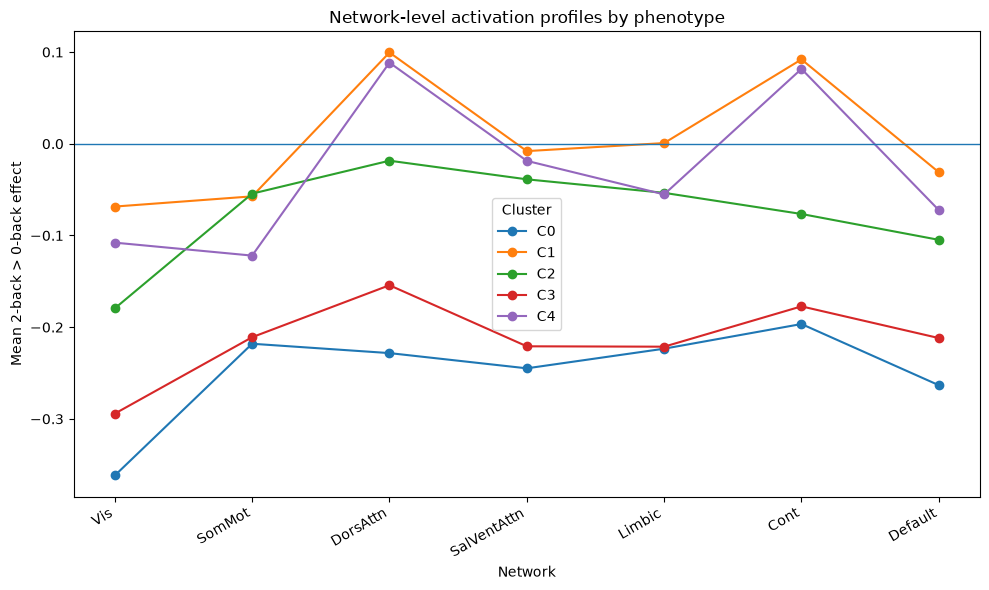

In [20]:
plt.figure(figsize=(10, 6))

for cluster in sorted(network_df["cluster"].unique()):
    means = (
        network_df.loc[
            network_df["cluster"] == cluster,
            network_order
        ]
        .mean()
    )

    plt.plot(
        network_order,
        means,
        marker="o",
        label=f"C{cluster}"
    )

plt.axhline(0, linewidth=1)

plt.ylabel("Mean 2-back > 0-back effect")
plt.xlabel("Network")
plt.title("Network-level activation profiles by phenotype")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "network_profiles_k5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
participants_file = OPENNEURO_DIR / "participants.tsv"

participants = pd.read_csv(
    participants_file,
    sep="\t"
)

print(participants.shape)

print(
    participants[
        ["participant_id", "age", "sex"]
    ].head()
)

print("\nAge missing:")
print(participants["age"].isna().sum())

print("\nSex:")
print(participants["sex"].value_counts(dropna=False))

(132, 17)
  participant_id  age sex
0      sub-19861   15   M
1      sub-20124   11   F
2      sub-20125   13   M
3      sub-20139   14   F
4      sub-20141   14   F

Age missing:
0

Sex:
sex
M    67
F    65
Name: count, dtype: int64


In [22]:
network_df = network_df.merge(
    participants[
        ["participant_id", "age", "sex"]
    ],
    on="participant_id",
    how="left",
    validate="one_to_one"
)

print("N =", len(network_df))

print("\nMissing covariates:")
print(
    network_df[
        ["age", "sex"]
    ].isna().sum()
)

display(
    network_df[
        ["participant_id", "cluster", "age", "sex"]
    ].head()
)

N = 77

Missing covariates:
age    0
sex    0
dtype: int64


,participant_id,cluster,age,sex
0,sub-19861,1,15,M
1,sub-20139,1,14,F
2,sub-20141,1,14,F
3,sub-20188,4,13,M
4,sub-20214,1,14,F


In [23]:
network_df["age_c"] = (
    network_df["age"]
    - network_df["age"].mean()
)

print(
    network_df[
        ["age", "age_c"]
    ].describe()
)

             age         age_c
count  77.000000  7.700000e+01
mean   12.324675  6.690175e-16
std     2.022515  2.022515e+00
min     8.000000 -4.324675e+00
25%    11.000000 -1.324675e+00
50%    13.000000  6.753247e-01
75%    14.000000  1.675325e+00
max    16.000000  3.675325e+00


In [24]:
network_df["sex_M"] = (
    network_df["sex"] == "M"
).astype(int)

print(
    pd.crosstab(
        network_df["sex"],
        network_df["sex_M"]
    )
)

sex_M   0   1
sex          
F      39   0
M       0  38


In [25]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

In [26]:
network_results = []
network_models = {}

for network in network_order:

    formula = (
        f"{network} ~ C(cluster) + age_c + sex_M"
    )

    model = smf.ols(
        formula,
        data=network_df
    ).fit()

    network_models[network] = model

    aov = anova_lm(
        model,
        typ=2
    )

    cluster_row = aov.loc["C(cluster)"]

    ss_cluster = cluster_row["sum_sq"]
    ss_error = aov.loc["Residual", "sum_sq"]

    partial_eta2 = (
        ss_cluster /
        (ss_cluster + ss_error)
    )

    network_results.append({
        "network": network,
        "F": cluster_row["F"],
        "df_cluster": cluster_row["df"],
        "df_residual": aov.loc["Residual", "df"],
        "p": cluster_row["PR(>F)"],
        "partial_eta2": partial_eta2
    })


network_results = pd.DataFrame(network_results)

display(
    network_results.round(4)
)

,network,F,df_cluster,df_residual,p,partial_eta2
0,Vis,2.5182,4.0,70.0,0.0489,0.1258
1,SomMot,1.4158,4.0,70.0,0.2378,0.0748
2,DorsAttn,6.6255,4.0,70.0,0.0001,0.2746
3,SalVentAttn,2.9306,4.0,70.0,0.0267,0.1434
4,Limbic,2.3865,4.0,70.0,0.0593,0.1200
5,Cont,4.9858,4.0,70.0,0.0014,0.2217
6,Default,2.0744,4.0,70.0,0.0934,0.1060


In [27]:
reject, p_fdr, _, _ = multipletests(
    network_results["p"],
    alpha=0.05,
    method="fdr_bh"
)

network_results["p_fdr"] = p_fdr
network_results["fdr_significant"] = reject

network_results = (
    network_results
    .sort_values("p")
    .reset_index(drop=True)
)

display(
    network_results.round(4)
)

,network,F,df_cluster,df_residual,p,partial_eta2,p_fdr,fdr_significant
0,DorsAttn,6.6255,4.0,70.0,0.0001,0.2746,0.0010,True
1,Cont,4.9858,4.0,70.0,0.0014,0.2217,0.0047,True
2,SalVentAttn,2.9306,4.0,70.0,0.0267,0.1434,0.0622,False
3,Vis,2.5182,4.0,70.0,0.0489,0.1258,0.0830,False
4,Limbic,2.3865,4.0,70.0,0.0593,0.1200,0.0830,False
5,Default,2.0744,4.0,70.0,0.0934,0.1060,0.1089,False
6,SomMot,1.4158,4.0,70.0,0.2378,0.0748,0.2378,False


In [28]:
network_results.to_csv(
    RESULTS_DIR /
    "network_cluster_omnibus_k5.csv",
    index=False
)

network_cluster_means.to_csv(
    RESULTS_DIR /
    "network_cluster_descriptives_k5.csv"
)

network_df.to_csv(
    DERIVED_DIR /
    "network_activation_k5.csv",
    index=False
)

print("Saved.")

Saved.


In [29]:
sig_networks = ["DorsAttn", "Cont"]

raw_summary = (
    network_df
    .groupby("cluster")[sig_networks]
    .agg(["count", "mean", "std"])
)

display(raw_summary.round(4))

DorsAttn                  Cont                
           count    mean     std count    mean     std
cluster                                               
0              6 -0.2283  0.2081     6 -0.1966  0.1928
1             34  0.0995  0.1781    34  0.0920  0.2079
2              6 -0.0185  0.0837     6 -0.0766  0.1509
3              6 -0.1543  0.0754     6 -0.1773  0.1128
4             25  0.0884  0.1900    25  0.0816  0.1926

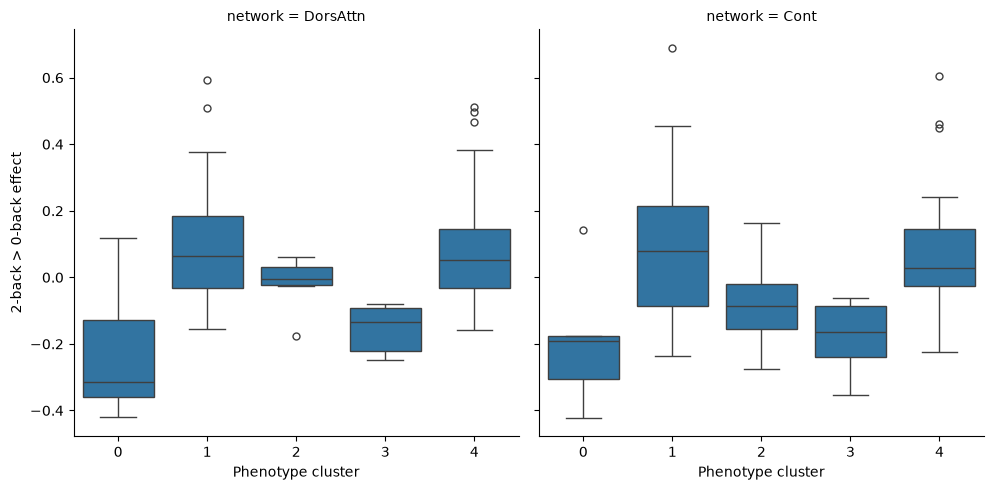

In [30]:
plot_df = network_df.melt(
    id_vars=["participant_id", "cluster"],
    value_vars=sig_networks,
    var_name="network",
    value_name="activation"
)

g = sns.catplot(
    data=plot_df,
    x="cluster",
    y="activation",
    col="network",
    kind="box",
    height=5,
    aspect=1
)

g.set_axis_labels(
    "Phenotype cluster",
    "2-back > 0-back effect"
)

plt.show()

In [31]:
pairwise_results = {}

for network in sig_networks:

    model = network_models[network]

    pw = model.t_test_pairwise(
        "C(cluster)",
        method="holm"
    )

    result = pw.result_frame.copy()
    result["network"] = network

    pairwise_results[network] = result

    print(f"\n===== {network} =====")
    display(result.round(4))


===== DorsAttn =====


,coef,std err,t,P>|t|,Conf. Int. Low,Conf. Int. Upp.,pvalue-holm,reject-holm,network
1-0,0.3392,0.0779,4.3545,0.0000,0.1838,0.4946,0.0004,True,DorsAttn
2-0,0.2401,0.1027,2.3370,0.0223,0.0352,0.4449,0.1338,False,DorsAttn
3-0,0.1219,0.1060,1.1498,0.2541,-0.0896,0.3334,1.0000,False,DorsAttn
4-0,0.3290,0.0795,4.1375,0.0001,0.1704,0.4876,0.0009,True,DorsAttn
2-1,-0.0991,0.0780,-1.2716,0.2077,-0.2547,0.0564,1.0000,False,DorsAttn
3-1,-0.2173,0.0807,-2.6926,0.0089,-0.3782,-0.0563,0.0709,False,DorsAttn
4-1,-0.0102,0.0472,-0.2158,0.8298,-0.1044,0.0840,1.0000,False,DorsAttn
3-2,-0.1181,0.1012,-1.1670,0.2472,-0.3200,0.0838,1.0000,False,DorsAttn
4-2,0.0890,0.0808,1.1007,0.2748,-0.0722,0.2501,1.0000,False,DorsAttn
4-3,0.2071,0.0841,2.4616,0.0163,0.0393,0.3749,0.1141,False,DorsAttn



===== Cont =====


,coef,std err,t,P>|t|,Conf. Int. Low,Conf. Int. Upp.,pvalue-holm,reject-holm,network
1-0,0.3052,0.0861,3.5452,0.0007,0.1335,0.4769,0.0070,True,Cont
2-0,0.1568,0.1135,1.3810,0.1717,-0.0696,0.3832,0.7044,False,Cont
3-0,0.0775,0.1172,0.6614,0.5105,-0.1562,0.3113,1.0000,False,Cont
4-0,0.2898,0.0879,3.2976,0.0015,0.1145,0.4651,0.0138,True,Cont
2-1,-0.1484,0.0862,-1.7226,0.0894,-0.3203,0.0234,0.5363,False,Cont
3-1,-0.2277,0.0892,-2.5532,0.0129,-0.4056,-0.0498,0.1028,False,Cont
4-1,-0.0154,0.0522,-0.2952,0.7687,-0.1196,0.0887,1.0000,False,Cont
3-2,-0.0793,0.1119,-0.7085,0.4810,-0.3024,0.1439,1.0000,False,Cont
4-2,0.1330,0.0893,1.4894,0.1409,-0.0451,0.3112,0.7044,False,Cont
4-3,0.2123,0.0930,2.2832,0.0255,0.0269,0.3977,0.1782,False,Cont


In [32]:
print(pairwise_results["DorsAttn"].columns)

Index(['coef', 'std err', 't', 'P>|t|', 'Conf. Int. Low', 'Conf. Int. Upp.',
       'pvalue-holm', 'reject-holm', 'network'],
      dtype='str')


Pairwise results saved.


In [34]:
adjusted_rows = []

for network in sig_networks:

    model = network_models[network]

    for cluster in sorted(network_df["cluster"].unique()):

        new_data = network_df[
            ["cluster", "age_c", "sex_M"]
        ].copy()

        new_data["cluster"] = cluster

        predicted = model.predict(new_data)

        adjusted_rows.append({
            "network": network,
            "cluster": cluster,
            "adjusted_mean": predicted.mean()
        })


adjusted_means = pd.DataFrame(adjusted_rows)

display(
    adjusted_means
    .pivot(
        index="cluster",
        columns="network",
        values="adjusted_mean"
    )
    .round(4)
)

network,Cont,DorsAttn
cluster,,
0,-0.2151,-0.2434
1,0.0901,0.0958
2,-0.0583,-0.0033
3,-0.1376,-0.1215
4,0.0747,0.0856


In [36]:
adjusted_means.to_csv(
    RESULTS_DIR /
    "network_adjusted_cluster_means_k5.csv",
    index=False
)

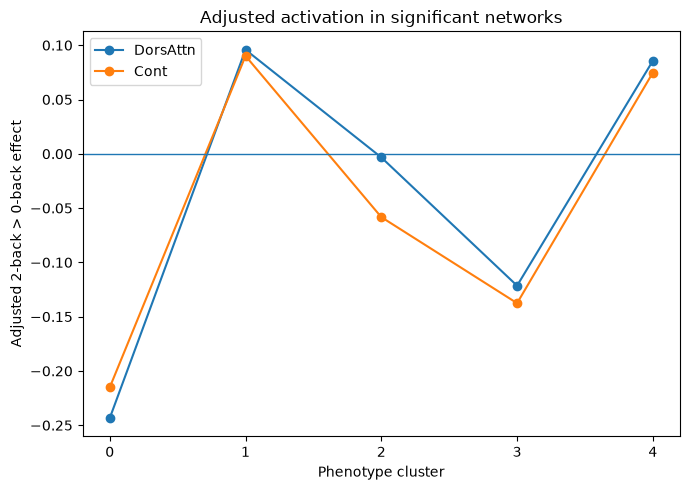

In [37]:
plt.figure(figsize=(7, 5))

for network in sig_networks:

    temp = adjusted_means[
        adjusted_means["network"] == network
    ]

    plt.plot(
        temp["cluster"],
        temp["adjusted_mean"],
        marker="o",
        label=network
    )

plt.axhline(0, linewidth=1)

plt.xlabel("Phenotype cluster")
plt.ylabel("Adjusted 2-back > 0-back effect")
plt.title("Adjusted activation in significant networks")
plt.xticks(sorted(network_df["cluster"].unique()))
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "significant_network_adjusted_profiles_k5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

['participant_id', 'session_id', 'cluster', 'n_maps', 'map_path']


,participant_id,session_id,cluster,n_maps,map_path
0,sub-19861,ses-1,1,1,/Users/hyuna/OpenNeuro/ds007116/derivatives/le...
1,sub-20139,ses-1,1,1,/Users/hyuna/OpenNeuro/ds007116/derivatives/le...
2,sub-20141,ses-1,1,1,/Users/hyuna/OpenNeuro/ds007116/derivatives/le...
3,sub-20188,ses-1,4,1,/Users/hyuna/OpenNeuro/ds007116/derivatives/le...
4,sub-20214,ses-1,1,1,/Users/hyuna/OpenNeuro/ds007116/derivatives/le...


In [43]:
for path in brain_cluster_df["map_path"].head(10):
    print(path)

/Users/hyuna/OpenNeuro/ds007116/derivatives/level-subject_task-fracback_model-rtdur/sub-19861/sub-19861_task-nback_space-MNI152NLin6Asym_contrast-twoBackMinusZeroBack_stat-effect_statmap.nii.gz
/Users/hyuna/OpenNeuro/ds007116/derivatives/level-subject_task-fracback_model-rtdur/sub-20139/sub-20139_task-nback_space-MNI152NLin6Asym_contrast-twoBackMinusZeroBack_stat-effect_statmap.nii.gz
/Users/hyuna/OpenNeuro/ds007116/derivatives/level-subject_task-fracback_model-rtdur/sub-20141/sub-20141_ses-1_task-nback_space-MNI152NLin6Asym_contrast-twoBackMinusZeroBack_stat-effect_statmap.nii.gz
/Users/hyuna/OpenNeuro/ds007116/derivatives/level-subject_task-fracback_model-rtdur/sub-20188/sub-20188_task-nback_space-MNI152NLin6Asym_contrast-twoBackMinusZeroBack_stat-effect_statmap.nii.gz
/Users/hyuna/OpenNeuro/ds007116/derivatives/level-subject_task-fracback_model-rtdur/sub-20214/sub-20214_task-nback_space-MNI152NLin6Asym_contrast-twoBackMinusZeroBack_stat-effect_statmap.nii.gz
/Users/hyuna/OpenNeuro/d

In [44]:
# Find official task-contrast QC file

qc_files = list(
    OPENNEURO_DIR.rglob("EF_desc-taskcontrast_qc.csv")
)

print("Found:", len(qc_files))

for p in qc_files:
    print(p)

Found: 0


In [46]:
search_roots = [
    Path("/Users/hyuna/data"),
    Path("/Users/hyuna/Downloads"),
    Path("/Users/hyuna/Documents"),
]

qc_files = []

for root in search_roots:
    if root.exists():
        qc_files.extend(
            root.rglob("EF_desc-taskcontrast_qc.csv")
        )

print("Found:", len(qc_files))

for p in qc_files:
    print(p)

Found: 1
/Users/hyuna/Downloads/transdiagnostic_executive_function/QC/qc_csvs/final_QC_csvs/EF_desc-taskcontrast_qc.csv


In [47]:
REPO_DIR = Path(
    "/Users/hyuna/Downloads/transdiagnostic_executive_function"
)

QC_FILE = (
    REPO_DIR
    / "QC"
    / "qc_csvs"
    / "final_QC_csvs"
    / "EF_desc-taskcontrast_qc.csv"
)

print(QC_FILE.exists())
print(QC_FILE)

True
/Users/hyuna/Downloads/transdiagnostic_executive_function/QC/qc_csvs/final_QC_csvs/EF_desc-taskcontrast_qc.csv


In [48]:
qc = pd.read_csv(QC_FILE)

print(qc.shape)
print(qc.columns.tolist())
display(qc.head())

(191, 8)
['participant_id', 'session_id', 'task', 'run', 'missing_events_tsv', 'response_time_all_na', 'failed_fmri_QC', 'qc_determination']


,participant_id,session_id,task,run,missing_events_tsv,response_time_all_na,failed_fmri_QC,qc_determination
0,19861,1,nback,1,pass,pass,pass,pass
1,19861,2,nback,1,pass,pass,pass,pass
2,20139,1,nback,1,pass,pass,pass,pass
3,20139,2,nback,1,pass,pass,pass,pass
4,20139,3,nback,1,pass,pass,pass,pass


In [50]:
print(qc["qc_determination"].value_counts(dropna=False))
print(qc["task"].value_counts(dropna=False))

qc_determination
pass    169
fail     22
Name: count, dtype: int64
task
nback    191
Name: count, dtype: int64


In [51]:
usable_qc = qc[
    (qc["task"] == "nback") &
    (qc["qc_determination"].str.lower() == "pass")
].copy()

print("Usable rows:", len(usable_qc))

display(
    usable_qc[
        ["participant_id", "session_id", "run", "qc_determination"]
    ].head(20)
)

Usable rows: 169


,participant_id,session_id,run,qc_determination
0,19861,1,1,pass
1,19861,2,1,pass
2,20139,1,1,pass
3,20139,2,1,pass
4,20139,3,1,pass
5,20141,1,1,pass
7,20149,2,1,pass
8,20149,3,1,pass
9,20188,1,1,pass
10,20188,2,1,pass


In [52]:
usable_sessions = (
    usable_qc[
        ["participant_id", "session_id"]
    ]
    .drop_duplicates()
    .groupby("participant_id")["session_id"]
    .apply(lambda x: sorted(x.astype(str).tolist()))
    .reset_index(name="usable_sessions")
)

display(usable_sessions.head(20))

,participant_id,usable_sessions
0,19861,"[1, 2]"
1,20139,"[1, 2, 3]"
2,20141,[1]
3,20149,"[2, 3]"
4,20188,"[1, 2, 3]"
5,20214,"[1, 3]"
6,20238,"[1, 2]"
7,20252,"[1, 2]"
8,20253,"[1, 2, 3]"
9,20258,[2]


In [54]:
print(brain_cluster_df["participant_id"].head())
print(brain_cluster_df["participant_id"].dtype)

print(usable_sessions["participant_id"].head())
print(usable_sessions["participant_id"].dtype)

0    sub-19861
1    sub-20139
2    sub-20141
3    sub-20188
4    sub-20214
Name: participant_id, dtype: str
str
0    19861
1    20139
2    20141
3    20149
4    20188
Name: participant_id, dtype: int64
int64


In [55]:
usable_sessions["participant_id"] = (
    usable_sessions["participant_id"]
    .astype(str)
    .str.replace(r"^sub-", "", regex=True)
    .apply(lambda x: f"sub-{x}")
)

print(usable_sessions["participant_id"].head())
print(usable_sessions["participant_id"].dtype)

0    sub-19861
1    sub-20139
2    sub-20141
3    sub-20149
4    sub-20188
Name: participant_id, dtype: str
str


In [56]:
brain_cluster_df["participant_id"] = (
    brain_cluster_df["participant_id"]
    .astype(str)
    .str.replace(r"^sub-", "", regex=True)
    .apply(lambda x: f"sub-{x}")
)

In [57]:
overlap = set(brain_cluster_df["participant_id"]) & set(
    usable_sessions["participant_id"]
)

print("Brain participants:", brain_cluster_df["participant_id"].nunique())
print("QC participants:", usable_sessions["participant_id"].nunique())
print("Overlap:", len(overlap))

Brain participants: 77
QC participants: 105
Overlap: 77


In [58]:
session_check = (
    brain_cluster_df[
        ["participant_id", "cluster", "map_path"]
    ]
    .merge(
        usable_sessions,
        on="participant_id",
        how="left",
        validate="one_to_one"
    )
)

session_check["includes_ses1"] = (
    session_check["usable_sessions"]
    .apply(
        lambda x:
        isinstance(x, list) and "ses-1" in x
    )
)

print("N =", len(session_check))
print("\nMissing session information:")
print(session_check["usable_sessions"].isna().sum())

print("\nSes-1 inclusion:")
print(session_check["includes_ses1"].value_counts())

print("\nBy cluster:")
print(
    pd.crosstab(
        session_check["cluster"],
        session_check["includes_ses1"]
    )
)

N = 77

Missing session information:
0

Ses-1 inclusion:
includes_ses1
False    77
Name: count, dtype: int64

By cluster:
includes_ses1  False
cluster             
0                  6
1                 34
2                  6
3                  6
4                 25


In [59]:
print("QC session_id unique values:")
print(qc["session_id"].unique())

print("\nusable_sessions examples:")
display(usable_sessions.head(15))

QC session_id unique values:
[1 2 3]

usable_sessions examples:


,participant_id,usable_sessions
0,sub-19861,"[1, 2]"
1,sub-20139,"[1, 2, 3]"
2,sub-20141,[1]
3,sub-20149,"[2, 3]"
4,sub-20188,"[1, 2, 3]"
5,sub-20214,"[1, 3]"
6,sub-20238,"[1, 2]"
7,sub-20252,"[1, 2]"
8,sub-20253,"[1, 2, 3]"
9,sub-20258,[2]


In [60]:
def normalize_session(x):
    x = str(x).strip().lower()

    # remove common prefixes
    x = x.replace("session-", "")
    x = x.replace("session", "")
    x = x.replace("ses-", "")
    x = x.replace("ses", "")

    # handle values such as "1.0"
    try:
        x = str(int(float(x)))
    except ValueError:
        pass

    return f"ses-{x}"

In [61]:
qc["session_id_norm"] = (
    qc["session_id"]
    .apply(normalize_session)
)

print(
    qc[
        ["session_id", "session_id_norm"]
    ]
    .drop_duplicates()
    .sort_values("session_id_norm")
)

   session_id session_id_norm
0           1           ses-1
1           2           ses-2
4           3           ses-3


In [62]:
usable_qc = qc[
    (qc["task"] == "nback") &
    (qc["qc_determination"].astype(str).str.lower() == "pass")
].copy()

usable_sessions = (
    usable_qc[
        ["participant_id", "session_id_norm"]
    ]
    .drop_duplicates()
    .groupby("participant_id")["session_id_norm"]
    .apply(lambda x: sorted(x.tolist()))
    .reset_index(name="usable_sessions")
)

In [63]:
usable_sessions["participant_id"] = (
    usable_sessions["participant_id"]
    .astype(str)
    .str.replace(r"^sub-", "", regex=True)
    .apply(lambda x: f"sub-{x}")
)

In [64]:
display(usable_sessions.head(20))

,participant_id,usable_sessions
0,sub-19861,"[ses-1, ses-2]"
1,sub-20139,"[ses-1, ses-2, ses-3]"
2,sub-20141,[ses-1]
3,sub-20149,"[ses-2, ses-3]"
4,sub-20188,"[ses-1, ses-2, ses-3]"
5,sub-20214,"[ses-1, ses-3]"
6,sub-20238,"[ses-1, ses-2]"
7,sub-20252,"[ses-1, ses-2]"
8,sub-20253,"[ses-1, ses-2, ses-3]"
9,sub-20258,[ses-2]


In [65]:
session_check = (
    brain_cluster_df[
        ["participant_id", "cluster", "map_path"]
    ]
    .merge(
        usable_sessions,
        on="participant_id",
        how="left",
        validate="one_to_one"
    )
)

session_check["includes_ses1"] = (
    session_check["usable_sessions"]
    .apply(
        lambda x:
        isinstance(x, list) and "ses-1" in x
    )
)

print("N =", len(session_check))

print("\nMissing session information:")
print(
    session_check["usable_sessions"]
    .isna()
    .sum()
)

print("\nSes-1 inclusion:")
print(
    session_check["includes_ses1"]
    .value_counts()
)

print("\nBy cluster:")
print(
    pd.crosstab(
        session_check["cluster"],
        session_check["includes_ses1"]
    )
)

N = 77

Missing session information:
0

Ses-1 inclusion:
includes_ses1
True     71
False     6
Name: count, dtype: int64

By cluster:
includes_ses1  False  True 
cluster                    
0                  0      6
1                  2     32
2                  3      3
3                  0      6
4                  1     24


In [66]:
ses1_info = session_check[
    ["participant_id", "includes_ses1"]
].copy()

network_ses1_df = (
    network_df
    .merge(
        ses1_info,
        on="participant_id",
        how="left",
        validate="one_to_one"
    )
)

network_ses1_df = (
    network_ses1_df[
        network_ses1_df["includes_ses1"]
    ]
    .copy()
)

print("Sensitivity N =", len(network_ses1_df))

print("\nCluster sizes:")
print(
    network_ses1_df["cluster"]
    .value_counts()
    .sort_index()
)

print("\nMissing covariates:")
print(
    network_ses1_df[
        ["age_c", "sex_M"]
    ].isna().sum()
)

Sensitivity N = 71

Cluster sizes:
cluster
0     6
1    32
2     3
3     6
4    24
Name: count, dtype: int64

Missing covariates:
age_c    0
sex_M    0
dtype: int64


In [67]:
sensitivity_results = []
sensitivity_models = {}

for network in network_order:

    formula = (
        f"{network} ~ C(cluster) + age_c + sex_M"
    )

    model = smf.ols(
        formula,
        data=network_ses1_df
    ).fit()

    sensitivity_models[network] = model

    aov = anova_lm(
        model,
        typ=2
    )

    cluster_row = aov.loc["C(cluster)"]

    ss_cluster = cluster_row["sum_sq"]
    ss_error = aov.loc["Residual", "sum_sq"]

    partial_eta2 = (
        ss_cluster /
        (ss_cluster + ss_error)
    )

    sensitivity_results.append({
        "network": network,
        "N": int(model.nobs),
        "F": cluster_row["F"],
        "df_cluster": cluster_row["df"],
        "df_residual": aov.loc["Residual", "df"],
        "p": cluster_row["PR(>F)"],
        "partial_eta2": partial_eta2
    })

sensitivity_results = pd.DataFrame(
    sensitivity_results
)

display(
    sensitivity_results.round(4)
)

,network,N,F,df_cluster,df_residual,p,partial_eta2
0,Vis,71,2.2823,4.0,64.0,0.0700,0.1248
1,SomMot,71,1.2955,4.0,64.0,0.2812,0.0749
2,DorsAttn,71,5.8924,4.0,64.0,0.0004,0.2692
3,SalVentAttn,71,2.8873,4.0,64.0,0.0292,0.1529
4,Limbic,71,2.1584,4.0,64.0,0.0837,0.1189
5,Cont,71,4.2217,4.0,64.0,0.0043,0.2088
6,Default,71,1.8228,4.0,64.0,0.1353,0.1023


In [68]:
reject, p_fdr, _, _ = multipletests(
    sensitivity_results["p"],
    alpha=0.05,
    method="fdr_bh"
)

sensitivity_results["p_fdr"] = p_fdr
sensitivity_results["fdr_significant"] = reject

sensitivity_results = (
    sensitivity_results
    .sort_values("p")
    .reset_index(drop=True)
)

display(
    sensitivity_results.round(4)
)

,network,N,F,df_cluster,df_residual,p,partial_eta2,p_fdr,fdr_significant
0,DorsAttn,71,5.8924,4.0,64.0,0.0004,0.2692,0.0030,True
1,Cont,71,4.2217,4.0,64.0,0.0043,0.2088,0.0150,True
2,SalVentAttn,71,2.8873,4.0,64.0,0.0292,0.1529,0.0680,False
3,Vis,71,2.2823,4.0,64.0,0.0700,0.1248,0.1172,False
4,Limbic,71,2.1584,4.0,64.0,0.0837,0.1189,0.1172,False
5,Default,71,1.8228,4.0,64.0,0.1353,0.1023,0.1579,False
6,SomMot,71,1.2955,4.0,64.0,0.2812,0.0749,0.2812,False


In [69]:
primary_compare = (
    network_results[
        [
            "network",
            "F",
            "p",
            "partial_eta2",
            "p_fdr",
            "fdr_significant"
        ]
    ]
    .rename(columns={
        "F": "F_primary",
        "p": "p_primary",
        "partial_eta2": "eta2_primary",
        "p_fdr": "p_fdr_primary",
        "fdr_significant": "sig_primary"
    })
)

sensitivity_compare = (
    sensitivity_results[
        [
            "network",
            "F",
            "p",
            "partial_eta2",
            "p_fdr",
            "fdr_significant"
        ]
    ]
    .rename(columns={
        "F": "F_ses1",
        "p": "p_ses1",
        "partial_eta2": "eta2_ses1",
        "p_fdr": "p_fdr_ses1",
        "fdr_significant": "sig_ses1"
    })
)

comparison = (
    primary_compare
    .merge(
        sensitivity_compare,
        on="network",
        how="inner"
    )
    .sort_values("p_primary")
)

display(
    comparison.round(4)
)

,network,F_primary,p_primary,eta2_primary,p_fdr_primary,sig_primary,F_ses1,p_ses1,eta2_ses1,p_fdr_ses1,sig_ses1
0,DorsAttn,6.6255,0.0001,0.2746,0.0010,True,5.8924,0.0004,0.2692,0.0030,True
1,Cont,4.9858,0.0014,0.2217,0.0047,True,4.2217,0.0043,0.2088,0.0150,True
2,SalVentAttn,2.9306,0.0267,0.1434,0.0622,False,2.8873,0.0292,0.1529,0.0680,False
3,Vis,2.5182,0.0489,0.1258,0.0830,False,2.2823,0.0700,0.1248,0.1172,False
4,Limbic,2.3865,0.0593,0.1200,0.0830,False,2.1584,0.0837,0.1189,0.1172,False
5,Default,2.0744,0.0934,0.1060,0.1089,False,1.8228,0.1353,0.1023,0.1579,False
6,SomMot,1.4158,0.2378,0.0748,0.2378,False,1.2955,0.2812,0.0749,0.2812,False


In [70]:
sensitivity_adjusted_rows = []

for network in ["DorsAttn", "Cont"]:

    model = sensitivity_models[network]

    for cluster in sorted(
        network_ses1_df["cluster"].unique()
    ):

        new_data = network_ses1_df[
            ["cluster", "age_c", "sex_M"]
        ].copy()

        new_data["cluster"] = cluster

        predicted = model.predict(new_data)

        sensitivity_adjusted_rows.append({
            "network": network,
            "cluster": cluster,
            "adjusted_mean": predicted.mean()
        })

sensitivity_adjusted_means = pd.DataFrame(
    sensitivity_adjusted_rows
)

display(
    sensitivity_adjusted_means
    .pivot(
        index="cluster",
        columns="network",
        values="adjusted_mean"
    )
    .round(4)
)

network,Cont,DorsAttn
cluster,,
0,-0.2123,-0.2415
1,0.0861,0.0930
2,0.0110,0.0246
3,-0.1417,-0.1229
4,0.0727,0.0852


In [71]:
# Save primary network-level results

primary_out = (
    network_results
    .sort_values("p")
    .reset_index(drop=True)
)

primary_out.to_csv(
    RESULTS_DIR / "network_ancova_primary_n77.csv",
    index=False
)

print(
    RESULTS_DIR / "network_ancova_primary_n77.csv"
)

/Users/hyuna/OpenNeuro/ds007116/results/summary_tables/network_ancova_primary_n77.csv


In [72]:
# Save ses-1 sensitivity results

sensitivity_results.to_csv(
    RESULTS_DIR / "network_ancova_sensitivity_ses1_n71.csv",
    index=False
)

comparison.to_csv(
    RESULTS_DIR / "network_primary_vs_sensitivity.csv",
    index=False
)

print("Saved sensitivity tables.")

Saved sensitivity tables.


In [73]:
# Model-adjusted means for all seven networks

adjusted_rows = []

for network in network_order:

    model = network_models[network]

    for cluster in sorted(network_df["cluster"].unique()):

        new_data = network_df[
            ["cluster", "age_c", "sex_M"]
        ].copy()

        new_data["cluster"] = cluster

        predicted = model.predict(new_data)

        adjusted_rows.append({
            "network": network,
            "cluster": cluster,
            "adjusted_mean": predicted.mean()
        })

adjusted_means = pd.DataFrame(adjusted_rows)

adjusted_table = (
    adjusted_means
    .pivot(
        index="cluster",
        columns="network",
        values="adjusted_mean"
    )
)

display(adjusted_table.round(4))

network,Cont,Default,DorsAttn,Limbic,SalVentAttn,SomMot,Vis
cluster,,,,,,,
0,-0.2151,-0.2738,-0.2434,-0.2323,-0.2587,-0.2247,-0.3725
1,0.0901,-0.0333,0.0958,0.0003,-0.0091,-0.0598,-0.0730
2,-0.0583,-0.0942,-0.0033,-0.0449,-0.0252,-0.0476,-0.1685
3,-0.1376,-0.1890,-0.1215,-0.2024,-0.1914,-0.1963,-0.2706
4,0.0747,-0.0747,0.0856,-0.0591,-0.0242,-0.1222,-0.1074


In [74]:
adjusted_table.to_csv(
    RESULTS_DIR / "network_adjusted_means_primary_n77.csv"
)

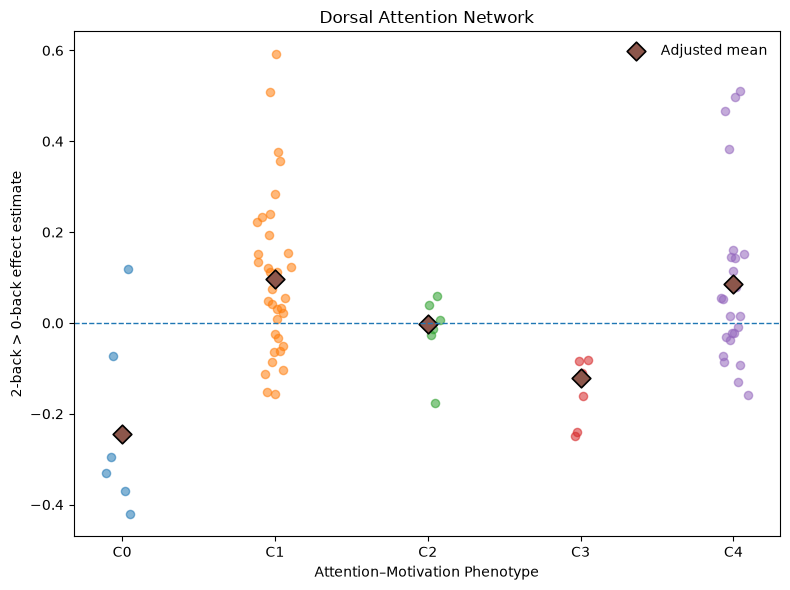

In [75]:
import matplotlib.pyplot as plt
import numpy as np

network = "DorsAttn"

fig, ax = plt.subplots(figsize=(8, 6))

# Individual observations
for cluster in sorted(network_df["cluster"].unique()):

    vals = network_df.loc[
        network_df["cluster"] == cluster,
        network
    ]

    # deterministic horizontal jitter
    rng = np.random.default_rng(42 + int(cluster))
    jitter = rng.normal(
        loc=cluster,
        scale=0.055,
        size=len(vals)
    )

    ax.scatter(
        jitter,
        vals,
        alpha=0.55,
        s=35
    )

# Adjusted means
means = (
    adjusted_means[
        adjusted_means["network"] == network
    ]
    .sort_values("cluster")
)

ax.scatter(
    means["cluster"],
    means["adjusted_mean"],
    marker="D",
    s=90,
    edgecolor="black",
    linewidth=1.2,
    label="Adjusted mean"
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xticks(range(5))
ax.set_xticklabels(
    [f"C{i}" for i in range(5)]
)

ax.set_xlabel("Attention–Motivation Phenotype")
ax.set_ylabel("2-back > 0-back effect estimate")
ax.set_title(
    "Dorsal Attention Network"
)

ax.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "network_dorsattn_primary_n77.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

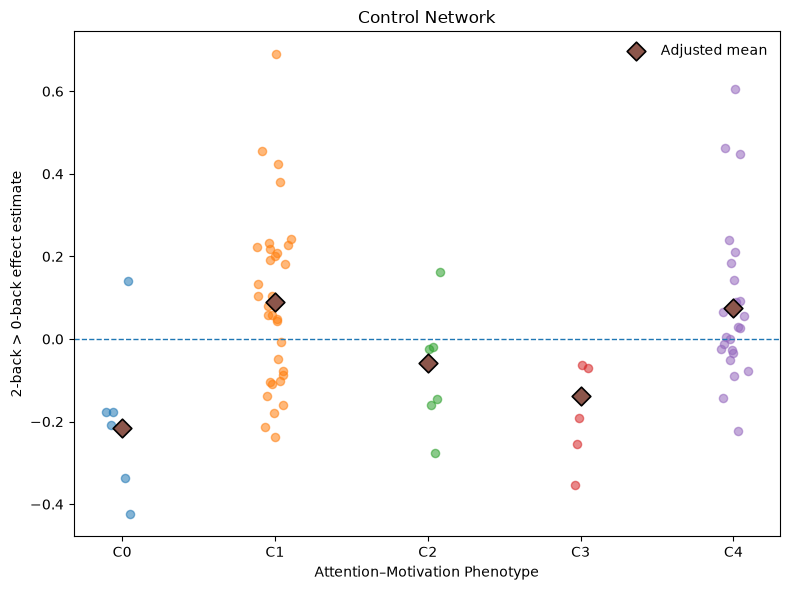

In [76]:
network = "Cont"

fig, ax = plt.subplots(figsize=(8, 6))

for cluster in sorted(network_df["cluster"].unique()):

    vals = network_df.loc[
        network_df["cluster"] == cluster,
        network
    ]

    rng = np.random.default_rng(42 + int(cluster))
    jitter = rng.normal(
        loc=cluster,
        scale=0.055,
        size=len(vals)
    )

    ax.scatter(
        jitter,
        vals,
        alpha=0.55,
        s=35
    )

means = (
    adjusted_means[
        adjusted_means["network"] == network
    ]
    .sort_values("cluster")
)

ax.scatter(
    means["cluster"],
    means["adjusted_mean"],
    marker="D",
    s=90,
    edgecolor="black",
    linewidth=1.2,
    label="Adjusted mean"
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)

ax.set_xticks(range(5))
ax.set_xticklabels(
    [f"C{i}" for i in range(5)]
)

ax.set_xlabel("Attention–Motivation Phenotype")
ax.set_ylabel("2-back > 0-back effect estimate")
ax.set_title(
    "Control Network"
)

ax.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "network_control_primary_n77.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

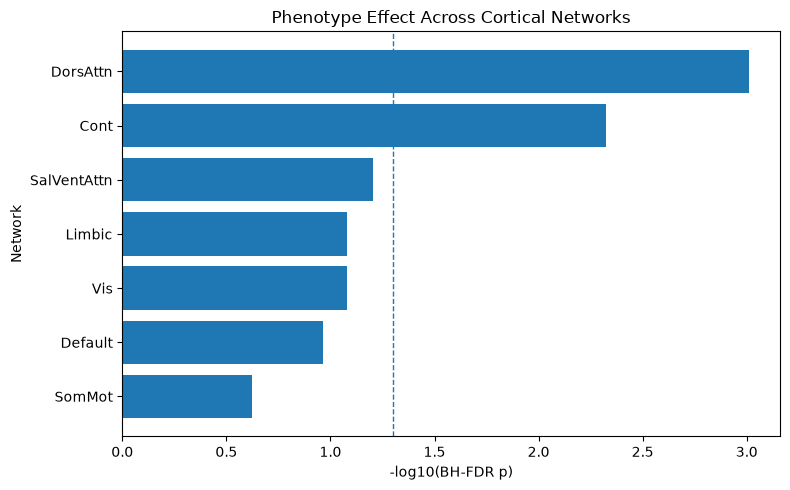

In [77]:
plot_df = (
    network_results
    .copy()
    .sort_values("p_fdr", ascending=False)
)

plot_df["minus_log10_fdr"] = (
    -np.log10(plot_df["p_fdr"])
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    plot_df["network"],
    plot_df["minus_log10_fdr"]
)

ax.axvline(
    -np.log10(0.05),
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("-log10(BH-FDR p)")
ax.set_ylabel("Network")
ax.set_title(
    "Phenotype Effect Across Cortical Networks"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "network_omnibus_fdr_primary_n77.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [78]:
posthoc_rows = []

for network in ["DorsAttn", "Cont"]:

    model = network_models[network]

    pw = model.t_test_pairwise(
        "C(cluster)",
        method="holm"
    ).result_frame.copy()

    pw = pw.reset_index().rename(
        columns={"index": "contrast"}
    )

    pw.insert(
        0,
        "network",
        network
    )

    posthoc_rows.append(pw)

posthoc_results = pd.concat(
    posthoc_rows,
    ignore_index=True
)

display(posthoc_results)

posthoc_results.to_csv(
    RESULTS_DIR / "network_posthoc_holm_primary_n77.csv",
    index=False
)

,network,contrast,coef,std err,t,P>|t|,Conf. Int. Low,Conf. Int. Upp.,pvalue-holm,reject-holm
0,DorsAttn,1-0,0.339211,0.077900,4.354462,0.000045,0.183845,0.494577,0.000447,True
1,DorsAttn,2-0,0.240063,0.102721,2.337047,0.022303,0.035193,0.444934,0.133818,False
2,DorsAttn,3-0,0.121929,0.106045,1.149787,0.254145,-0.089571,0.333430,1.000000,False
3,DorsAttn,4-0,0.329017,0.079521,4.137473,0.000096,0.170417,0.487617,0.000867,True
4,DorsAttn,2-1,-0.099148,0.077972,-1.271578,0.207732,-0.254659,0.056363,1.000000,False
5,DorsAttn,3-1,-0.217282,0.080695,-2.692644,0.008863,-0.378222,-0.056342,0.070904,False
6,DorsAttn,4-1,-0.010194,0.047245,-0.215779,0.829788,-0.104422,0.084033,1.000000,False
7,DorsAttn,3-2,-0.118134,0.101231,-1.166974,0.247181,-0.320033,0.083765,1.000000,False
8,DorsAttn,4-2,0.088953,0.080816,1.100691,0.274802,-0.072229,0.250135,1.000000,False
9,DorsAttn,4-3,0.207087,0.084129,2.461553,0.016301,0.039298,0.374877,0.114105,False


In [79]:
sensitivity_adjusted_table = (
    sensitivity_adjusted_means
    .pivot(
        index="cluster",
        columns="network",
        values="adjusted_mean"
    )
)

sensitivity_adjusted_table.to_csv(
    RESULTS_DIR /
    "network_adjusted_means_sensitivity_ses1_n71.csv"
)

display(
    sensitivity_adjusted_table.round(4)
)

network,Cont,DorsAttn
cluster,,
0,-0.2123,-0.2415
1,0.0861,0.0930
2,0.0110,0.0246
3,-0.1417,-0.1229
4,0.0727,0.0852


In [80]:
brain_sample_provenance = session_check[
    [
        "participant_id",
        "cluster",
        "map_path",
        "usable_sessions",
        "includes_ses1"
    ]
].copy()

# list -> readable string for csv
brain_sample_provenance["usable_sessions"] = (
    brain_sample_provenance["usable_sessions"]
    .apply(lambda x: ";".join(x))
)

brain_sample_provenance.to_csv(
    DERIVED_DIR / "brain_sample_provenance.csv",
    index=False
)

display(
    brain_sample_provenance.head()
)

,participant_id,cluster,map_path,usable_sessions,includes_ses1
0,sub-19861,1,/Users/hyuna/OpenNeuro/ds007116/derivatives/le...,ses-1;ses-2,True
1,sub-20139,1,/Users/hyuna/OpenNeuro/ds007116/derivatives/le...,ses-1;ses-2;ses-3,True
2,sub-20141,1,/Users/hyuna/OpenNeuro/ds007116/derivatives/le...,ses-1,True
3,sub-20188,4,/Users/hyuna/OpenNeuro/ds007116/derivatives/le...,ses-1;ses-2;ses-3,True
4,sub-20214,1,/Users/hyuna/OpenNeuro/ds007116/derivatives/le...,ses-1;ses-3,True


## Network-level results

Among the 92 participants included in baseline phenotype construction, 77 had an available subject-level `2-back > 0-back` effect map from the official RT-duration GLM pipeline.

Network-level activation was summarized using the Schaefer 100-parcel, 7-network cortical atlas. For each network, an OLS ANCOVA tested the omnibus effect of phenotype while adjusting for age and sex. Multiple comparisons across the seven network-level tests were controlled using the Benjamini–Hochberg false discovery rate (FDR).

Significant phenotype effects were observed in the dorsal attention network (F(4,70) = 6.63, FDR p = .001, partial η² = .275) and control network (F(4,70) = 4.99, FDR p = .005, partial η² = .222). No other network survived FDR correction.

Follow-up pairwise contrasts were conducted only for the two networks showing significant omnibus effects, with Holm correction across the 10 pairwise phenotype comparisons within each network. In both the dorsal attention and control networks, Cluster 0 showed significantly lower load-related activation than Clusters 1 and 4 after correction. Other pairwise contrasts did not survive Holm correction.

The network profiles therefore indicated that the phenotype differences were not distributed uniformly across the cortex, but were most evident in large-scale systems involved in goal-directed attention and cognitive control. These effects should be interpreted as differences in `2-back > 0-back` contrast estimates rather than differences in general neural activation or direct measures of attentional ability.

## Sensitivity analysis: neural estimates including baseline fMRI

The official subject-level GLM combined all QC-eligible n-back runs/sessions available for each participant. Therefore, the primary neural estimates were not restricted to baseline fMRI.

To evaluate whether the primary findings depended on participants whose neural estimates contained only later-session data, a sensitivity analysis was performed among participants whose subject-level estimate included `ses-1` fMRI data (N = 71).

The dorsal attention network remained significant (F(4,64) = 5.89, FDR p = .003, partial η² = .269), as did the control network (F(4,64) = 4.22, FDR p = .015, partial η² = .209). The adjusted phenotype profiles were highly similar to those observed in the primary N = 77 analysis.

Thus, the primary network-level findings were not attributable to the six participants whose neural estimates did not include baseline fMRI. This sensitivity analysis does not constitute a baseline-only fMRI analysis, because estimates for some participants still incorporated multiple QC-eligible sessions.

## Summary

Baseline-defined attention–motivation phenotypes were associated with differential working-memory load-related activation in the dorsal attention and control networks.

The effects survived FDR correction across seven cortical networks and were robust to exclusion of participants whose subject-level neural estimates did not include baseline fMRI. Follow-up contrasts indicated that Cluster 0, characterized behaviorally by elevated hyperactivity/impulsivity and markedly reduced CPT sensitivity, showed lower dorsal attention and control network contrast estimates than Clusters 1 and 4.

Because phenotype membership was defined independently of the fMRI data, these findings provide neural characterization of the behaviorally derived phenotypes. However, they do not establish a neural mechanism underlying phenotype formation, and the small size of several clusters—particularly Cluster 0 (n = 6)—requires caution in interpreting specific pairwise differences.

The network analysis provides a broad systems-level characterization. Spatially localized whole-brain analyses are examined separately.

In [81]:
covariates = (
    network_df[
        ["participant_id", "age", "sex", "age_c", "sex_M"]
    ]
    .drop_duplicates("participant_id")
    .copy()
)

covariates.to_csv(
    DERIVED_DIR / "brain_covariates_n77.csv",
    index=False
)

print(covariates.shape)
display(covariates.head())

(77, 5)


,participant_id,age,sex,age_c,sex_M
0,sub-19861,15,M,2.675325,1
1,sub-20139,14,F,1.675325,0
2,sub-20141,14,F,1.675325,0
3,sub-20188,13,M,0.675325,1
4,sub-20214,14,F,1.675325,0
